In [15]:
%pip install matplotlib pandas seaborn joblib scikit-learn kaggle hub

     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/643.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/6

ERROR: Exception:
Traceback (most recent call last):
  File "c:\Users\DARSHIL\OneDrive\Desktop\Major_Project\venv\lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "c:\Users\DARSHIL\OneDrive\Desktop\Major_Project\venv\lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
  File "c:\Users\DARSHIL\OneDrive\Desktop\Major_Project\venv\lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
  File "c:\Users\DARSHIL\OneDrive\Desktop\Major_Project\venv\lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(amt)
  File "C:\Users\DARSHIL\AppData\Local\Programs\Python\Python38\lib\http\client.py", line 455, in read
    n = self.readinto(b)
  File "C:\Users\DARSHIL\AppData\Local\Programs\Python\Python38\lib\http\client.py", line 499, in re

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer 

In [17]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [18]:
%pip install xgboost


Note: you may need to restart the kernel to use updated packages.


In [22]:
%pip install -U "kagglehub[pandas-datasets]"


Note: you may need to restart the kernel to use updated packages.


In [26]:

import kagglehub
import pandas as pd
import os

# Download the dataset
dataset_path = kagglehub.dataset_download(
    "shivamb/real-or-fake-fake-jobposting-prediction"
)

print("Dataset downloaded to:", dataset_path)

# Find CSV files automatically
csv_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:", csv_files)

# Load the dataset
if csv_files:
    file_path = next(
        (f for f in csv_files
         if os.path.basename(f).lower() == "fake_job_postings.csv"),
        csv_files[0]
    )

    df = pd.read_csv(file_path)

    print("\nDataset loaded successfully!")
    print(df.head())
    print("Shape:", df.shape)
else:
    print("No CSV file found in the downloaded dataset.")


Dataset downloaded to: C:\Users\DARSHIL\.cache\kagglehub\datasets\shivamb\real-or-fake-fake-jobposting-prediction\versions\1
CSV files found: ['C:\\Users\\DARSHIL\\.cache\\kagglehub\\datasets\\shivamb\\real-or-fake-fake-jobposting-prediction\\versions\\1\\fake_job_postings.csv']

Dataset loaded successfully!
   job_id                                      title            location  \
0       1                           Marketing Intern    US, NY, New York   
1       2  Customer Service - Cloud Video Production      NZ, , Auckland   
2       3    Commissioning Machinery Assistant (CMA)       US, IA, Wever   
3       4          Account Executive - Washington DC  US, DC, Washington   
4       5                        Bill Review Manager  US, FL, Fort Worth   

  department salary_range                                    company_profile  \
0  Marketing          NaN  We're Food52, and we've created a groundbreaki...   
1    Success          NaN  90 Seconds, the worlds Cloud Video Production 

In [25]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "fake_job_postings.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "shivamb/real-or-fake-fake-jobposting-prediction",
    file_path
)

print(df.head())
print(df.shape)

ImportError: cannot import name 'KaggleDatasetAdapter' from 'kagglehub' (c:\Users\DARSHIL\OneDrive\Desktop\Major_Project\venv\lib\site-packages\kagglehub\__init__.py)

In [27]:
df.head()


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [28]:
df["text"] = (
 df["title"].fillna(" ") + ""
    + df["company_profile"].fillna(" ") + " "
    + df["description"].fillna(" ") + " "
    + df["requirements"].fillna(" ")
)



df.drop(columns=["title", "company_profile", "description", "requirements","job_id","location","department","benefits","function","industry"], inplace=True)
df.head(5)

,salary_range,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,fraudulent,text
0,NaN,0,1,0,Other,Internship,NaN,0,"Marketing InternWe're Food52, and we've create..."
1,NaN,0,1,0,Full-time,Not Applicable,NaN,0,Customer Service - Cloud Video Production90 Se...
2,NaN,0,1,0,NaN,NaN,NaN,0,Commissioning Machinery Assistant (CMA)Valor S...
3,NaN,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,0,Account Executive - Washington DCOur passion f...
4,NaN,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,0,Bill Review ManagerSpotSource Solutions LLC is...


In [ ]:
# print(df.shape)
# print(df.info())
# print(df.isnull().sum())
# print(df.duplicated().sum())

# print(df["fraudulent"].value_counts())

In [ ]:
df

,salary_range,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,fraudulent,text
0,NaN,0,1,0,Other,Internship,NaN,0,"Marketing InternWe're Food52, and we've create..."
1,NaN,0,1,0,Full-time,Not Applicable,NaN,0,Customer Service - Cloud Video Production90 Se...
2,NaN,0,1,0,NaN,NaN,NaN,0,Commissioning Machinery Assistant (CMA)Valor S...
3,NaN,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,0,Account Executive - Washington DCOur passion f...
4,NaN,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,0,Bill Review ManagerSpotSource Solutions LLC is...
...,...,...,...,...,...,...,...,...,...
17875,NaN,0,1,1,Full-time,Mid-Senior level,NaN,0,Account Director - Distribution Vend is lookin...
17876,NaN,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,0,Payroll AccountantWebLinc is the e-commerce pl...
17877,NaN,0,0,0,Full-time,NaN,NaN,0,Project Cost Control Staff Engineer - Cost Con...
17878,NaN,0,0,1,Contract,Not Applicable,Professional,0,Graphic Designer Nemsia Studios is looking fo...


3.Fill missing values in categorical columns


cal_col = []

In [29]:
cat_col = ["employment_type","required_experience","required_education"]
for col in cat_col:
    df[col] = df[col].fillna("unknown")

num_col = ['telecommuting', 'has_company_logo', 'has_questions']

4. Train/test split(stratify because fraud is rare)

In [30]:
X = df[['text']+cat_col+num_col]
y = df['fraudulent']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


# for xgboost
X = df[['text'] + cat_col + num_col]
y = df['fraudulent']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

5. Column Transformer: different processing for different columns

In [31]:
preprocessor = ColumnTransformer(transformers=[
    ('text', CountVectorizer(), 'text'),
    ('cat',OneHotEncoder(handle_unknown='ignore'), cat_col),
    ('num', 'passthrough', num_col)
])



6. Pipeling: preprocessing + model

In [32]:
model = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter = 1000, class_weight = 'balanced'))
])
model.fit(X_train, y_train)

# for xgboost
# Handle class imbalance
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

model_1 = Pipeline(steps=[
    ('preprocessor', ColumnTransformer(transformers=[
        ('text', CountVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2
        ), 'text'),

        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_col),

        ('num', 'passthrough', num_col)
    ])),

    ('classifier', XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric='logloss',
        tree_method='hist',
        random_state=42,
        n_jobs=-1
    ))
])

model_1.fit(X_train, y_train)




Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('text',
                                                  CountVectorizer(max_features=50000,
                                                                  min_df=2,
                                                                  ngram_range=(1,
                                                                               2)),
                                                  'text'),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['employment_type',
                                                   'required_experience',
                                                   'required_education']),
                                                 ('num', 'passthrough',
                                                  ['telecommuting',
                                                   'has_company_logo',
                                                   'has_questions'])])),
                ('classifier',
                 XGBCl...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, random_state=42, ...))])

7. Evaluate

In [33]:
y_pred = model_1.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

joblib.dump(model_1, 'fake_job_posting_model.pkl')
print("Model saved as 'fake_job_posting_model.pkl'")

Accuracy: 0.9885346756152126
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3403
           1       0.91      0.85      0.88       173

    accuracy                           0.99      3576
   macro avg       0.95      0.92      0.94      3576
weighted avg       0.99      0.99      0.99      3576

Model saved as 'fake_job_posting_model.pkl'


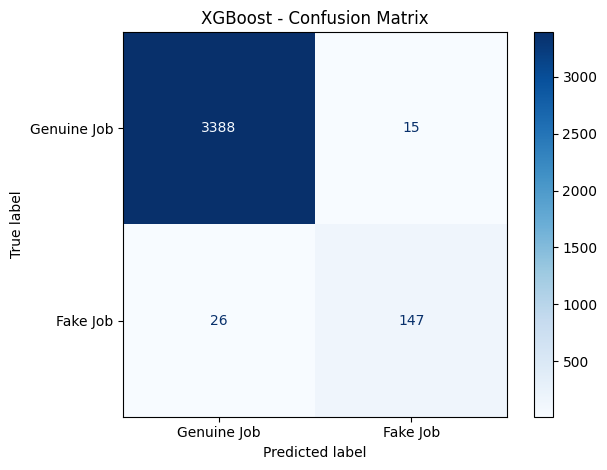

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    model_1,
    X_test,
    y_test,
    display_labels=["Genuine Job", "Fake Job"],
    cmap="Blues",
    values_format="d"
)

plt.title("XGBoost - Confusion Matrix")
plt.tight_layout()
plt.show()

In [21]:
pip show scikit-learn


Name: scikit-learn
Version: 1.3.2
Summary: A set of python modules for machine learning and data mining
Home-page: http://scikit-learn.org
Author: 
Author-email: 
License: new BSD
Location: c:\users\darshil\onedrive\desktop\major_project\venv\lib\site-packages
Requires: joblib, numpy, scipy, threadpoolctl
Required-by: 
Note: you may need to restart the kernel to use updated packages.
